# 📘 Exercice 2 – Analyse des données éducatives

## 🔹 Étape 1 – Exploration des données

Nous importons les fichiers fournis :  

- **EdStatsCountry.csv** : métadonnées sur les pays (codes, régions, groupes de revenu, etc.)  
- **EdStatsData.csv** : données principales (indicateurs, valeurs par année et pays)  
- **EdStatsFootNote.csv** : notes de bas de page associées aux données  
- **EdStatsCountry-Series.csv** : métadonnées sur les séries d’indicateurs  


In [1]:

import pandas as pd
import numpy as np
import os
import seaborn as sns
import matplotlib.pyplot as plt

print("\n============================")
print("ETAPE 1 - CHARGEMENT DES FICHIERS CSV")
print("============================")

EdStatsCountry = pd.read_csv("D:/formation/Data_Engineer_Bac_5/Projet_2/Projet+Python_Dataset_Edstats_csv/EdStatsCountry.csv")
EdStatsData = pd.read_csv("D:/formation/Data_Engineer_Bac_5/Projet_2/Projet+Python_Dataset_Edstats_csv/EdStatsData.csv")
EdStatsFootNote = pd.read_csv("D:/formation/Data_Engineer_Bac_5/Projet_2/Projet+Python_Dataset_Edstats_csv/EdStatsFootNote.csv")
EdStatsCountry_Series = pd.read_csv("D:/formation/Data_Engineer_Bac_5/Projet_2/Projet+Python_Dataset_Edstats_csv/EdStatsCountry-Series.csv")

print("✅ Tous les fichiers ont été importés avec succès.")



ETAPE 1 - CHARGEMENT DES FICHIERS CSV
✅ Tous les fichiers ont été importés avec succès.


In [2]:
print("\n============================")
print("ETAPE 1B - APPROCHE METIER")
print("============================")

# Charger la table des séries (catégories des indicateurs)
EdStatsSeries = pd.read_csv("D:/formation/Data_Engineer_Bac_5/Projet_2/Projet+Python_Dataset_Edstats_csv/EdStatsSeries.csv")

# Aperçu des catégories métier disponibles
print("Catégories d'indicateurs disponibles :")
print(EdStatsSeries['Topic'].value_counts().head(20))

# 👉 Choisir les catégories pertinentes selon l’objectif du projet
categories_gardees = [
    "Access to Education",
    "Completion",
    "Learning Outcomes",
    "Teachers",
    "Public Expenditure"
]

# Liste des indicateurs métier
indicateurs_metier = EdStatsSeries.loc[EdStatsSeries['Topic'].isin(categories_gardees), 'Indicator Name'].unique()
print("\nNombre d'indicateurs retenus (approche métier) :", len(indicateurs_metier))

# Filtrer EdStatsData
EdStatsData_metier = EdStatsData[EdStatsData['Indicator Name'].isin(indicateurs_metier)].copy()

# Vérifier années disponibles
annees = [c for c in EdStatsData_metier.columns if c.isdigit()]
annees_int = np.array(list(map(int, annees)))
print("Années disponibles :", annees_int.min(), "→", annees_int.max())

# 👉 Suppression des années futures (ex : > 2023)
annees_gardees = [str(y) for y in annees_int if y <= 2023]
colonnes_utiles = ["Country Code", "Indicator Name"] + annees_gardees
EdStatsData_metier = EdStatsData_metier[colonnes_utiles]

print("✅ Étape 1B terminée : jeu de données filtré par métier et années réalistes")
print("Indicateurs retenus :", EdStatsData_metier['Indicator Name'].nunique())



ETAPE 1B - APPROCHE METIER
Catégories d'indicateurs disponibles :
Topic
Learning Outcomes                                   1046
Attainment                                           733
Education Equality                                   426
Secondary                                            256
Primary                                              248
Population                                           213
Tertiary                                             158
Teachers                                             137
Expenditures                                          93
Engaging the Private Sector (SABER)                   51
Literacy                                              32
Teachers (SABER)                                      29
School Autonomy and Accountability (SABER)            29
Early Childhood Education                             24
Education Management Information Systems (SABER)      23
Post-Secondary/Non-Tertiary                           19
School Finance 

## 🔹 Étape 2 – Analyse exploratoire

Nous réalisons une **analyse exploratoire** :
- aperçu des 5 premières lignes,  
- dimensions des fichiers,  
- colonnes disponibles,  
- doublons,  
- valeurs manquantes,  
- statistiques descriptives,  
- distribution des valeurs catégorielles.  


In [3]:

print("\n============================")
print("ETAPE 2 - EXPLORATION DES DONNÉES")
print("============================")

# --- Aperçu des fichiers ---
print("\n[1] Aperçu des 5 premières lignes de chaque fichier :")
print("\n-- EdStatsCountry --")
print(EdStatsCountry.head())
print("\n-- EdStatsData --")
print(EdStatsData.head())
print("\n-- EdStatsFootNote --")
print(EdStatsFootNote.head())
print("\n-- EdStatsCountry-Series --")
print(EdStatsCountry_Series.head())

# --- Dimensions des fichiers ---
print("\n[2] Dimensions de chaque fichier (lignes, colonnes) :")
print("EdStatsCountry :", EdStatsCountry.shape)
print("EdStatsData :", EdStatsData.shape)
print("EdStatsFootNote :", EdStatsFootNote.shape)
print("EdStatsCountry-Series :", EdStatsCountry_Series.shape)

# --- Colonnes disponibles ---
print("\n[3] Colonnes de chaque fichier :")
print("EdStatsCountry :", EdStatsCountry.columns)
print("EdStatsData :", EdStatsData.columns)
print("EdStatsFootNote :", EdStatsFootNote.columns)
print("EdStatsCountry-Series :", EdStatsCountry_Series.columns)



ETAPE 2 - EXPLORATION DES DONNÉES

[1] Aperçu des 5 premières lignes de chaque fichier :

-- EdStatsCountry --
  Country Code   Short Name   Table Name                     Long Name  \
0          ABW        Aruba        Aruba                         Aruba   
1          AFG  Afghanistan  Afghanistan  Islamic State of Afghanistan   
2          AGO       Angola       Angola   People's Republic of Angola   
3          ALB      Albania      Albania           Republic of Albania   
4          AND      Andorra      Andorra       Principality of Andorra   

  2-alpha code   Currency Unit  \
0           AW   Aruban florin   
1           AF  Afghan afghani   
2           AO  Angolan kwanza   
3           AL    Albanian lek   
4           AD            Euro   

                                       Special Notes  \
0  SNA data for 2000-2011 are updated from offici...   
1  Fiscal year end: March 20; reporting period fo...   
2  April 2013 database update: Based on IMF data,...   
3             

In [4]:
print("\n============================")
print("ETAPE 2B - APPROCHE DATA")
print("============================")

# Restructurer en format long
long = EdStatsData_metier.melt(
    id_vars=["Country Code", "Indicator Name"],
    value_vars=annees_gardees,
    var_name="Annee", value_name="Valeur"
)

# --- Proportion d’indicateurs renseignés par année ---
ind_annee_renseigne = (
    long.groupby(["Annee", "Indicator Name"])["Valeur"].apply(lambda s: s.notna().any())
    .reset_index(name="has_value")
)
prop_indicateurs_par_annee = ind_annee_renseigne.groupby("Annee")["has_value"].mean()
print("\nProportion d’indicateurs renseignés par année :")
print(prop_indicateurs_par_annee.head())

# --- Proportion d’années renseignées par indicateur ---
annee_renseignee_par_indic = (
    long.groupby(["Indicator Name", "Annee"])["Valeur"].apply(lambda s: s.notna().any())
    .unstack("Annee").fillna(False)
)
prop_annees_par_indicateur = annee_renseignee_par_indic.mean(axis=1).sort_values(ascending=False)
print("\nTop 5 indicateurs par complétude temporelle :")
print(prop_annees_par_indicateur.head())

# --- Richesse en données (nb de pays renseignés par indicateur et année) ---
indicateurs_annees = (
    long.dropna(subset=["Valeur"])
    .groupby(["Indicator Name", "Annee"])["Country Code"].nunique()
    .reset_index(name="nb_pays")
)

# Moyenne sur toutes les années par indicateur
indicateurs_riches = (
    indicateurs_annees.groupby("Indicator Name")["nb_pays"].mean()
    .sort_values(ascending=False)
)

# Sélection finale (~15 indicateurs riches et pertinents métier)
indicateurs_selectionnes = indicateurs_riches.head(15).index.tolist()
print("\n✅ Liste finale des indicateurs sélectionnés (~15) :")
print(indicateurs_selectionnes)



ETAPE 2B - APPROCHE DATA

Proportion d’indicateurs renseignés par année :
Annee
1970    0.014925
1971    0.019315
1972    0.019315
1973    0.019315
1974    0.019315
Name: has_value, dtype: float64

Top 5 indicateurs par complétude temporelle :
Indicator Name
Teachers in secondary education, both sexes (number)                  0.959184
Teachers in tertiary education programmes, both sexes (number)        0.959184
Teachers in tertiary education programmes, female (number)            0.959184
Percentage of teachers in pre-primary education who are female (%)    0.959184
Pupil-teacher ratio in tertiary education (headcount basis)           0.959184
dtype: float64

✅ Liste finale des indicateurs sélectionnés (~15) :
['Teachers in primary education, both sexes (number)', 'Pupil-teacher ratio in primary education (headcount basis)', 'Teachers in primary education, female (number)', 'Percentage of teachers in primary education who are female (%)', 'Teachers in secondary education, both sexes

In [5]:

print("\n============================")
print("ETAPE 3 - ANALYSE EXPLORATOIRE")
print("============================")

# --- Doublons ---
print("\n[1] Nombre de doublons par fichier :")
print("EdStatsCountry :", EdStatsCountry.duplicated().sum())
print("EdStatsData :", EdStatsData.duplicated().sum())
print("EdStatsFootNote :", EdStatsFootNote.duplicated().sum())
print("EdStatsCountry-Series :", EdStatsCountry_Series.duplicated().sum())

# --- Valeurs manquantes ---
print("\n[2] Valeurs manquantes par fichier :")
print("EdStatsCountry :", EdStatsCountry.isnull().sum())
print("EdStatsData :", EdStatsData.isnull().sum())
print("EdStatsFootNote :", EdStatsFootNote.isnull().sum())
print("EdStatsCountry-Series :", EdStatsCountry_Series.isnull().sum())

# --- Proportion de valeurs manquantes ---
print("\n[3] Proportion de valeurs manquantes (en %) :")
print("EdStatsCountry :", EdStatsCountry.isnull().mean())
print("EdStatsData :", EdStatsData.isnull().mean())
print("EdStatsFootNote :", EdStatsFootNote.isnull().mean())
print("EdStatsCountry-Series :", EdStatsCountry_Series.isnull().mean())

# --- Statistiques descriptives ---
print("\n[4] Statistiques descriptives (colonnes numériques uniquement) :")
print("EdStatsCountry :")
print(EdStatsCountry.describe())
print("EdStatsData :")
print(EdStatsData.describe())

# --- Valeurs uniques sur colonnes catégorielles ---
print("\n[5] Analyse des colonnes catégorielles (value_counts) :")
print("EdStatsCountry - Region :")
print(EdStatsCountry['Region'].value_counts())
print("\nEdStatsCountry - Income Group :")
print(EdStatsCountry['Income Group'].value_counts())
print("\nEdStatsData - Indicator Name (Top 10) :")
print(EdStatsData['Indicator Name'].value_counts().head(10))
print("\nEdStatsFootNote - CountryCode (Top 10) :")
print(EdStatsFootNote['CountryCode'].value_counts().head(10))
print("\nEdStatsCountry-Series - CountryCode (Top 10) :")
print(EdStatsCountry_Series['CountryCode'].value_counts().head(10))

print("\n✅ Analyse exploratoire terminée.")



ETAPE 3 - ANALYSE EXPLORATOIRE

[1] Nombre de doublons par fichier :
EdStatsCountry : 0
EdStatsData : 0
EdStatsFootNote : 0
EdStatsCountry-Series : 0

[2] Valeurs manquantes par fichier :
EdStatsCountry : Country Code                                           0
Short Name                                             0
Table Name                                             0
Long Name                                              0
2-alpha code                                           3
Currency Unit                                         26
Special Notes                                         96
Region                                                27
Income Group                                          27
WB-2 code                                              1
National accounts base year                           36
National accounts reference year                     209
SNA price valuation                                   44
Lending category                                     

In [6]:
print("\n============================")
print("ETAPE 3B - CONSOLIDATION")
print("============================")

# Filtrer le long dataset avec les indicateurs retenus
df_filtre = long[
    long["Indicator Name"].isin(indicateurs_selectionnes)
].dropna(subset=["Valeur"])

# Agrégation (moyenne des années par pays et indicateur)
df_consolide = df_filtre.pivot_table(
    index="Country Code",
    columns="Indicator Name",
    values="Valeur",
    aggfunc="mean"
)

print("✅ DataFrame consolidé construit avec dimensions :", df_consolide.shape)
df_consolide.head()



ETAPE 3B - CONSOLIDATION
✅ DataFrame consolidé construit avec dimensions : (234, 15)


Indicator Name,Percentage of teachers in pre-primary education who are female (%),Percentage of teachers in primary education who are female (%),Percentage of teachers in secondary education who are female (%),Pupil-teacher ratio in pre-primary education (headcount basis),Pupil-teacher ratio in primary education (headcount basis),Pupil-teacher ratio in secondary education (headcount basis),"Teachers in pre-primary education, both sexes (number)","Teachers in pre-primary education, female (number)","Teachers in primary education, both sexes (number)","Teachers in primary education, female (number)","Teachers in secondary education, both sexes (number)","Teachers in secondary education, female (number)","Teachers in secondary general education, both sexes (number)","Teachers in secondary general education, female (number)","Teachers in tertiary education programmes, both sexes (number)"
Country Code,,,,,,,,,,,,,,,
ABW,99.035758,81.458409,53.837389,21.425129,17.708820,14.487491,134.071429,132.714286,553.357143,452.769231,493.000000,267.357143,373.166667,187.833333,185.294118
AFG,100.000000,28.478612,25.612964,17.002238,41.505385,26.203206,557.400000,557.400000,60727.727273,17869.900000,16606.272727,5302.800000,44012.400000,13128.200000,2370.230769
AGO,40.461990,33.762423,31.280576,34.303115,36.162794,18.814224,18463.000000,7470.500000,39426.444444,28690.666667,14735.375000,5689.250000,15502.500000,4050.000000,2102.666667
ALB,100.000000,79.990475,60.193278,20.377388,20.322734,15.402846,4316.026316,4319.027027,11331.000000,9025.250000,23323.250000,14053.916667,21561.100000,13240.888889,2512.880000
AND,91.611016,76.565670,59.496940,13.561206,10.809283,7.753728,181.600000,166.600000,386.375000,297.125000,482.428571,288.428571,431.666667,258.833333,98.900000


## 🔹 Étape 4 – Réduction du périmètre (Approche Data)

L’objectif est de **garder uniquement les indicateurs et années les plus riches en données**.  
Nous allons :  
1. Calculer la proportion d’indicateurs renseignés par année,  
2. Calculer la proportion d’années renseignées par indicateur,  
3. Créer un DataFrame `(indicateur, année, nb_pays)`,  
4. Identifier les indicateurs les plus riches,  
5. Sélectionner une quinzaine d’indicateurs pertinents.  


In [7]:

print("\n============================")
print("ETAPE 4 - REDUCTION DU PERIMETRE (APPROCHE DATA)")
print("============================")

# On garde uniquement les colonnes utiles : Country Code, Indicator Name, et les années
annees_colonnes = [col for col in EdStatsData.columns if col.isdigit()]
print(f"Colonnes d'années détectées : {annees_colonnes[:5]} ... {annees_colonnes[-5:]}")

# ============================
# 1. Proportion d’indicateurs renseignés par année
# ============================
print("\n[1] Proportion d’indicateurs renseignés par année")

proportion_indicateurs_par_annee = EdStatsData[annees_colonnes].notnull().mean()
print(proportion_indicateurs_par_annee.head())

# ============================
# 2. Proportion d’années renseignées par indicateur
# ============================
print("\n[2] Proportion d’années renseignées par indicateur")

proportion_annees_par_indicateur = EdStatsData.set_index("Indicator Name")[annees_colonnes].notnull().mean(axis=1)
print(proportion_annees_par_indicateur.head())

# ============================
# 3. DataFrame riche : nombre de pays par indicateur et par année
# ============================
print("\n[3] Création du DataFrame indicateur-année")

EdStatsData_long = EdStatsData.melt(
    id_vars=["Country Code", "Indicator Name"],
    value_vars=annees_colonnes,
    var_name="Annee",
    value_name="Valeur"
)

indicateurs_annees = (
    EdStatsData_long.dropna(subset=["Valeur"])
    .groupby(["Indicator Name", "Annee"])["Country Code"].nunique()
    .reset_index(name="nb_pays")
)

print(indicateurs_annees.head())

# ============================
# 4. Tri des indicateurs les plus riches
# ============================
print("\n[4] Indicateurs les plus riches (top 10 par nb de pays en moyenne)")

indicateurs_riches = (
    indicateurs_annees.groupby("Indicator Name")["nb_pays"]
    .mean()
    .sort_values(ascending=False)
)

print(indicateurs_riches.head(10))

# ============================
# 5. Sélection finale (quinzaine d’indicateurs)
# ============================
print("\n[5] Sélection d'une quinzaine d’indicateurs pertinents")

indicateurs_selectionnes = indicateurs_riches.head(15).index.tolist()
print("Liste des indicateurs sélectionnés :")
for ind in indicateurs_selectionnes:
    print(" -", ind)



ETAPE 4 - REDUCTION DU PERIMETRE (APPROCHE DATA)
Colonnes d'années détectées : ['1970', '1971', '1972', '1973', '1974'] ... ['2080', '2085', '2090', '2095', '2100']

[1] Proportion d’indicateurs renseignés par année
1970    0.081504
1971    0.040067
1972    0.040160
1973    0.040076
1974    0.040285
dtype: float64

[2] Proportion d’années renseignées par indicateur
Indicator Name
Adjusted net enrolment rate, lower secondary, both sexes (%)               0.000000
Adjusted net enrolment rate, lower secondary, female (%)                   0.000000
Adjusted net enrolment rate, lower secondary, gender parity index (GPI)    0.000000
Adjusted net enrolment rate, lower secondary, male (%)                     0.000000
Adjusted net enrolment rate, primary, both sexes (%)                       0.692308
dtype: float64

[3] Création du DataFrame indicateur-année
                                      Indicator Name Annee  nb_pays
0  Adjusted net enrolment rate, lower secondary, ...  1970        4
1

## 🔹 Étape 5 – Consolidation des données (pays, indicateur)

Nous restructurons les données pour obtenir un **DataFrame consolidé** :  
- Lignes = pays,  
- Colonnes = indicateurs sélectionnés,  
- Valeurs = moyenne des années disponibles.  


In [8]:

print("\n============================")
print("ETAPE 5 - CONSOLIDATION DES DONNÉES (pays, indicateur)")
print("============================")

EdStatsData_filtre = EdStatsData_long[
    EdStatsData_long["Indicator Name"].isin(indicateurs_selectionnes)
].dropna(subset=["Valeur"])

print(f"Dimensions après filtrage : {EdStatsData_filtre.shape}")
print(EdStatsData_filtre.head())

# Pivot_table pour agréger
df_consolide = EdStatsData_filtre.pivot_table(
    index="Country Code",
    columns="Indicator Name",
    values="Valeur",
    aggfunc="mean"
)

print("\nAperçu du DataFrame final :")
print(df_consolide.head())
print("\nDimensions du DataFrame consolidé :", df_consolide.shape)



ETAPE 5 - CONSOLIDATION DES DONNÉES (pays, indicateur)
Dimensions après filtrage : (154926, 4)
     Country Code                                     Indicator Name Annee  \
2307          ARB                       Population growth (annual %)  1970   
2317          ARB  Population of the official age for pre-primary...  1970   
2419          ARB                 Population, ages 0-14 (% of total)  1970   
2420          ARB                      Population, ages 0-14, female  1970   
2421          ARB                        Population, ages 0-14, male  1970   

            Valeur  
2307  2.767219e+00  
2317  9.425367e+06  
2419  4.471794e+01  
2420  2.702534e+07  
2421  2.815700e+07  

Aperçu du DataFrame final :
Indicator Name  Population growth (annual %)  \
Country Code                                   
ABW                                 1.232726   
AFG                                 2.469997   
AGO                                 3.121988   
ALB                                 0.68

## ✅ Conclusion

- Exploration complète des fichiers,  
- Réduction du périmètre (sélection d’indicateurs et d’années riches en données),  
- Consolidation finale `(pays, indicateur)` prête pour l’analyse ou la modélisation.  


In [9]:
print("\n============================")
print("ETAPE 6 - ANALYSE DES CORRELATIONS ET REDONDANCES")
print("============================")



ETAPE 6 - ANALYSE DES CORRELATIONS ET REDONDANCES


In [10]:
# --- Nettoyage des données : suppression des pays trop incomplets
df_corr = df_consolide.dropna(thresh=int(df_consolide.shape[1]*0.7))  # garder les pays avec ≥70% des indicateurs
df_corr = df_corr.fillna(df_corr.mean())  # imputation simple des valeurs manquantes par la moyenne

print("Dimensions après nettoyage :", df_corr.shape)

Dimensions après nettoyage : (219, 15)



Matrice de corrélation (Pearson) :
Indicator Name                                      Population growth (annual %)  \
Indicator Name                                                                     
Population growth (annual %)                                                1.00   
Population of the official age for pre-primary ...                         -0.02   
Population, ages 0-14 (% of total)                                          0.68   
Population, ages 0-14, female                                              -0.01   
Population, ages 0-14, male                                                -0.01   
Population, ages 0-14, total                                               -0.01   
Population, ages 15-64 (% of total)                                        -0.53   
Population, ages 15-64, female                                             -0.04   
Population, ages 15-64, male                                               -0.04   
Population, ages 15-64, total           

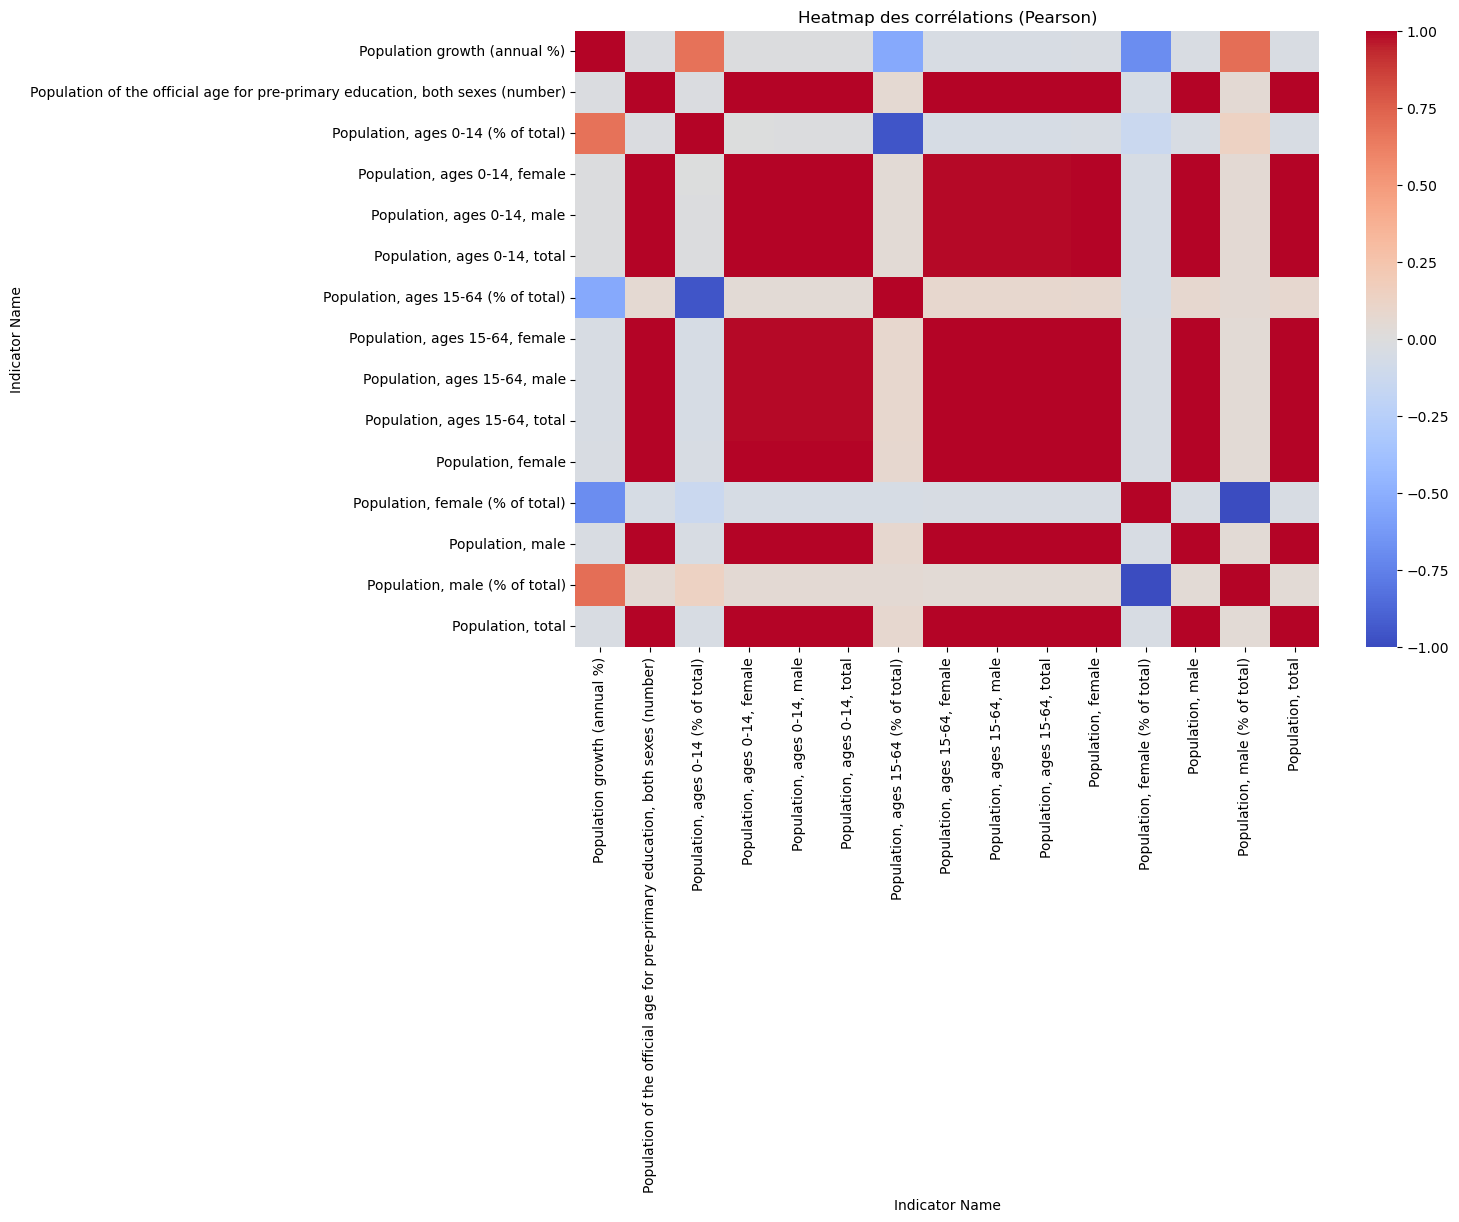

In [11]:
# --- Corrélation Pearson
corr_pearson = df_corr.corr(method="pearson")
print("\nMatrice de corrélation (Pearson) :")
print(corr_pearson.round(2))

plt.figure(figsize=(12,8))
sns.heatmap(corr_pearson, annot=False, cmap="coolwarm", center=0)
plt.title("Heatmap des corrélations (Pearson)")
plt.show()


Matrice de corrélation (Spearman) :
Indicator Name                                      Population growth (annual %)  \
Indicator Name                                                                     
Population growth (annual %)                                                1.00   
Population of the official age for pre-primary ...                          0.10   
Population, ages 0-14 (% of total)                                          0.82   
Population, ages 0-14, female                                               0.14   
Population, ages 0-14, male                                                 0.13   
Population, ages 0-14, total                                                0.13   
Population, ages 15-64 (% of total)                                        -0.74   
Population, ages 15-64, female                                             -0.02   
Population, ages 15-64, male                                               -0.00   
Population, ages 15-64, total          

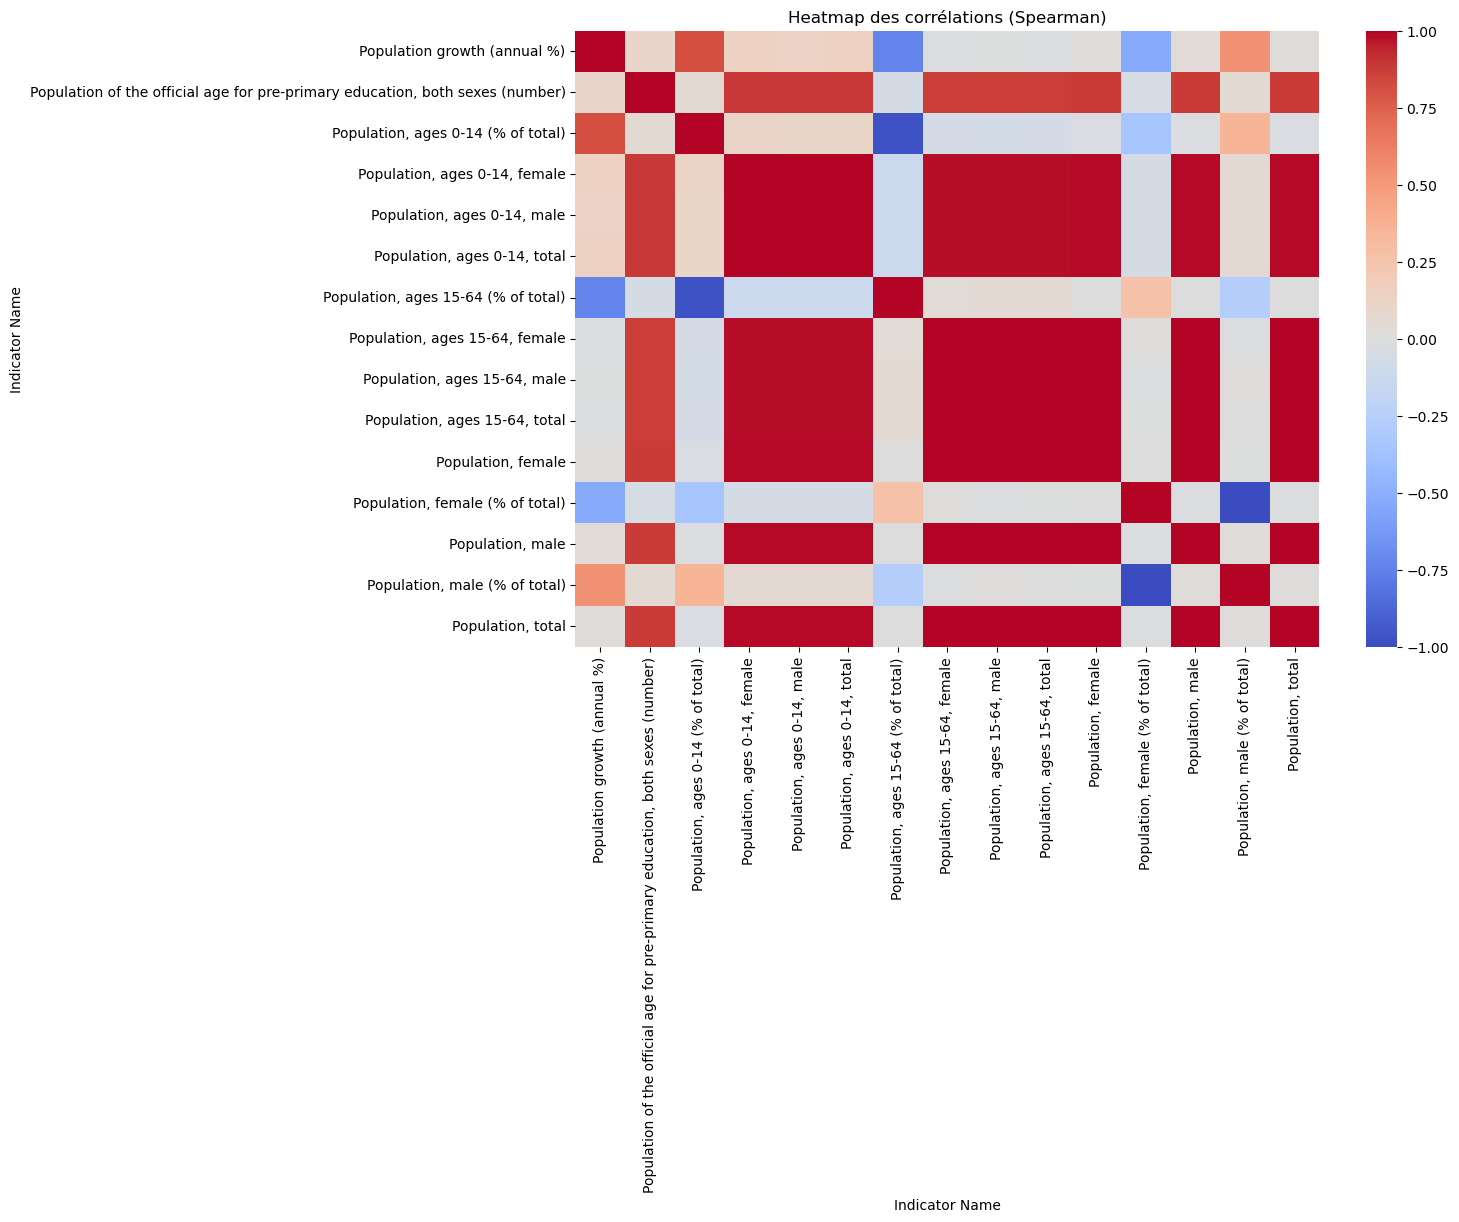

In [12]:
# --- Corrélation Spearman
corr_spearman = df_corr.corr(method="spearman")
print("\nMatrice de corrélation (Spearman) :")
print(corr_spearman.round(2))

plt.figure(figsize=(12,8))
sns.heatmap(corr_spearman, annot=False, cmap="coolwarm", center=0)
plt.title("Heatmap des corrélations (Spearman)")
plt.show()

In [13]:
# --- Détection des indicateurs trop corrélés (|corr| > 0.7)
seuil = 0.7
correlated_features = set()

for i in range(len(corr_pearson.columns)):
    for j in range(i):
        if abs(corr_pearson.iloc[i, j]) > seuil:
            colname = corr_pearson.columns[i]
            correlated_features.add(colname)

print("\nIndicateurs jugés redondants (corrélation > 0.7) :")
print(correlated_features)



Indicateurs jugés redondants (corrélation > 0.7) :
{'Population, male', 'Population, ages 15-64, total', 'Population, total', 'Population, male (% of total)', 'Population, female', 'Population, ages 15-64 (% of total)', 'Population, ages 0-14, total', 'Population, ages 15-64, male', 'Population, ages 15-64, female', 'Population, ages 0-14, female', 'Population, ages 0-14, male'}


In [14]:
# --- Création du DataFrame final sans redondances
df_final = df_corr.drop(columns=correlated_features, errors="ignore")

print("\nDimensions du DataFrame final :", df_final.shape)
print("Aperçu du DataFrame filtré :")
print(df_final.head())


Dimensions du DataFrame final : (219, 4)
Aperçu du DataFrame filtré :
Indicator Name  Population growth (annual %)  \
Country Code                                   
ABW                                 1.232726   
AFG                                 2.469997   
AGO                                 3.121988   
ALB                                 0.687773   
ARB                                 2.590034   

Indicator Name  Population of the official age for pre-primary education, both sexes (number)  \
Country Code                                                                                    
ABW                                                  2.492809e+03                               
AFG                                                  2.250407e+06                               
AGO                                                  1.071467e+06                               
ALB                                                  1.762557e+05                               
ARB       

In [15]:
print("\n============================")
print("ETAPE 7 - ANALYSE DESCRIPTIVE D'UN INDICATEUR")
print("============================")



ETAPE 7 - ANALYSE DESCRIPTIVE D'UN INDICATEUR



Analyse de l'indicateur : Population growth (annual %)
count    219.000000
mean       1.740456
std        1.171847
min       -0.379458
25%        0.758465
50%        1.804788
75%        2.521894
max        8.121829
Name: Population growth (annual %), dtype: float64


<Figure size 800x500 with 0 Axes>

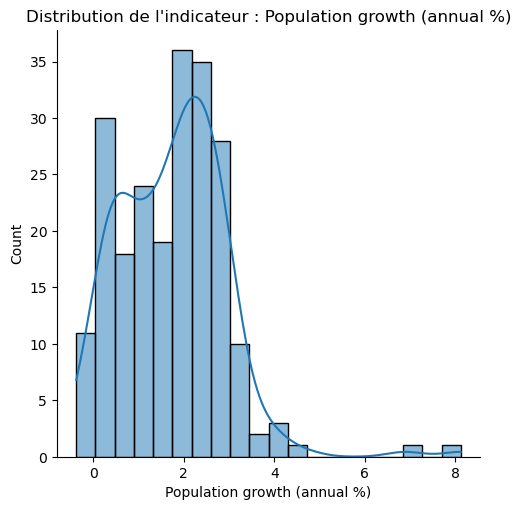


ETAPE 8 - GENERALISATION A TOUS LES INDICATEURS


In [16]:
# --- Choix d'un indicateur (exemple : première colonne du df_final)
indicateur_test = df_final.columns[0]

print(f"\nAnalyse de l'indicateur : {indicateur_test}")
print(df_final[indicateur_test].describe())

plt.figure(figsize=(8,5))
sns.displot(df_final[indicateur_test], kde=True, bins=20)
plt.title(f"Distribution de l'indicateur : {indicateur_test}")
plt.show()


print("\n============================")
print("ETAPE 8 - GENERALISATION A TOUS LES INDICATEURS")
print("============================")


In [17]:
# --- Fonction générique d'analyse
def analyse_indicateur(df, col):
    print(f"\n--- Indicateur : {col} ---")
    print(df[col].describe())
    
    plt.figure(figsize=(8,5))
    sns.displot(df[col], kde=True, bins=20)
    plt.title(f"Distribution de l'indicateur : {col}")
    plt.show()


In [18]:
# --- Fonction générique d'analyse
def analyse_indicateur(df, col):
    print(f"\n--- Indicateur : {col} ---")
    print(df[col].describe())
    
    plt.figure(figsize=(8,5))
    sns.displot(df[col], kde=True, bins=20)
    plt.title(f"Distribution de l'indicateur : {col}")
    plt.show()


--- Indicateur : Population growth (annual %) ---
count    219.000000
mean       1.740456
std        1.171847
min       -0.379458
25%        0.758465
50%        1.804788
75%        2.521894
max        8.121829
Name: Population growth (annual %), dtype: float64


<Figure size 800x500 with 0 Axes>

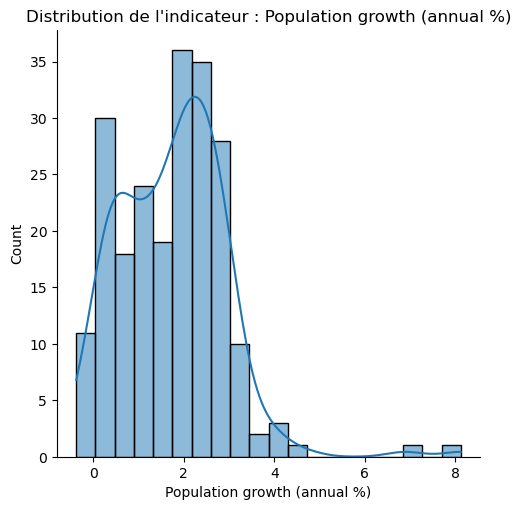


--- Indicateur : Population of the official age for pre-primary education, both sexes (number) ---
count    2.190000e+02
mean     1.010296e+07
std      3.681034e+07
min      2.492809e+03
25%      1.331845e+05
50%      4.731985e+05
75%      2.082961e+06
max      3.128665e+08
Name: Population of the official age for pre-primary education, both sexes (number), dtype: float64


<Figure size 800x500 with 0 Axes>

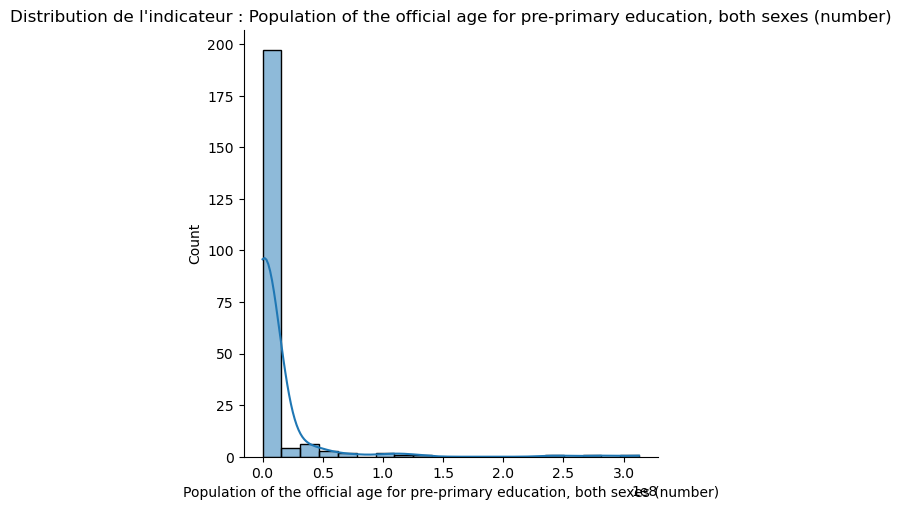


--- Indicateur : Population, ages 0-14 (% of total) ---
count    219.000000
mean      33.856082
std        9.476599
min       16.655921
25%       24.907515
50%       35.529528
75%       42.443453
max       48.841217
Name: Population, ages 0-14 (% of total), dtype: float64


<Figure size 800x500 with 0 Axes>

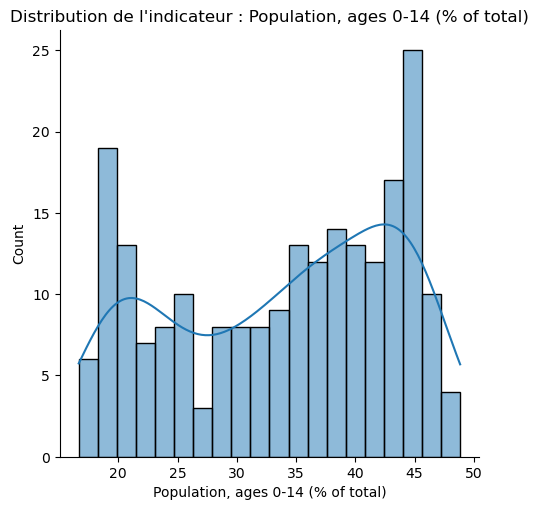


--- Indicateur : Population, female (% of total) ---
count    219.000000
mean      50.095539
std        2.288027
min       31.303905
25%       49.673213
50%       50.361786
75%       50.954517
max       53.957126
Name: Population, female (% of total), dtype: float64


<Figure size 800x500 with 0 Axes>

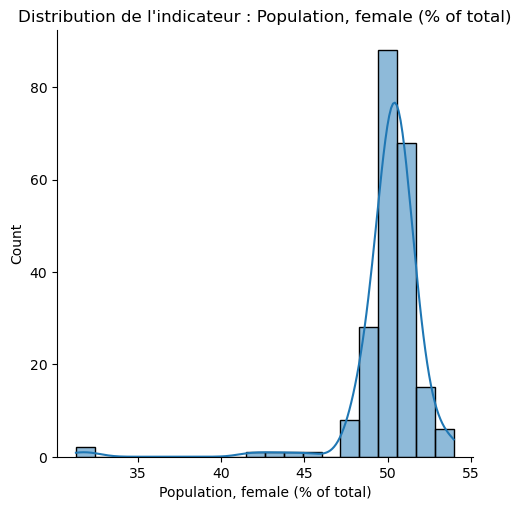

In [19]:
# --- Application à tous les indicateurs restants
for col in df_final.columns:
    analyse_indicateur(df_final, col)
    

In [20]:
print("\n============================")
print("ETAPE 9 - SELECTION DES PAYS PERTINENTS")
print("============================")

# --- Méthode simple : Top 5 par indicateur
top_pays = {}

for col in df_final.columns:
    top = df_final[col].nlargest(5).index.tolist()
    top_pays[col] = top
    print(f"\nTop 5 pays pour l'indicateur {col} : {top}")


ETAPE 9 - SELECTION DES PAYS PERTINENTS

Top 5 pays pour l'indicateur Population growth (annual %) : ['ARE', 'QAT', 'KWT', 'BHR', 'OMN']

Top 5 pays pour l'indicateur Population of the official age for pre-primary education, both sexes (number) : ['WLD', 'LMY', 'MIC', 'UMC', 'LMC']

Top 5 pays pour l'indicateur Population, ages 0-14 (% of total) : ['NER', 'UGA', 'AGO', 'YEM', 'ZMB']

Top 5 pays pour l'indicateur Population, female (% of total) : ['LVA', 'UKR', 'RUS', 'EST', 'BLR']


In [21]:
# --- Compter les occurrences des pays dans les différents top 5
from collections import Counter

all_top_pays = [p for sublist in top_pays.values() for p in sublist]
compteur_pays = Counter(all_top_pays)

print("\nOccurrences des pays dans les différents top 5 :")
print(compteur_pays.most_common())


Occurrences des pays dans les différents top 5 :
[('ARE', 1), ('QAT', 1), ('KWT', 1), ('BHR', 1), ('OMN', 1), ('WLD', 1), ('LMY', 1), ('MIC', 1), ('UMC', 1), ('LMC', 1), ('NER', 1), ('UGA', 1), ('AGO', 1), ('YEM', 1), ('ZMB', 1), ('LVA', 1), ('UKR', 1), ('RUS', 1), ('EST', 1), ('BLR', 1)]


In [22]:
# --- Liste finale des pays pertinents (ceux apparaissant le plus souvent)
pays_pertinents = [p for p, freq in compteur_pays.items() if freq >= 2]
print("\nListe finale de pays pertinents (au moins 2 apparitions dans les top 5) :")
print(pays_pertinents)


print("\n============================")
print("ETAPE 10 - SCORE GLOBAL (OPTIONNEL)")
print("============================")



Liste finale de pays pertinents (au moins 2 apparitions dans les top 5) :
[]

ETAPE 10 - SCORE GLOBAL (OPTIONNEL)


In [23]:
# --- Normalisation des indicateurs entre 0 et 1
df_norm = (df_final - df_final.min()) / (df_final.max() - df_final.min())

In [24]:
# --- Score global par pays (moyenne simple des indicateurs normalisés)
df_norm["Score_Global"] = df_norm.mean(axis=1)

In [25]:
# --- Classement des pays
classement_pays = df_norm["Score_Global"].sort_values(ascending=False)
print("\nTop 10 pays par score global :")
print(classement_pays.head(10))


Top 10 pays par score global :
Country Code
WLD    0.627768
LMY    0.623698
MIC    0.584615
NER    0.572866
UGA    0.564387
AGO    0.562230
SSA    0.557718
SSF    0.557702
YEM    0.554438
HPC    0.553457
Name: Score_Global, dtype: float64


In [26]:
# --- Liste finale de pays selon score global
pays_pertinents_score = classement_pays.head(10).index.tolist()
print("\nListe finale de pays (méthode score global) :")
print(pays_pertinents_score)


Liste finale de pays (méthode score global) :
['WLD', 'LMY', 'MIC', 'NER', 'UGA', 'AGO', 'SSA', 'SSF', 'YEM', 'HPC']
